# 43 · Representative problems

**Question.** How do the two forms compare on the three problems that test them hardest: a stiff equation (R2c), an exact kernel (R3a) and two axes (R5b)?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p2_reproduction", "p5_build", "p5_t3")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p2_reproduction: 327 records, 327 ok
p5_build: 224 records, 224 ok
p5_t3: 192 records, 192 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import reference_builds
from pihm.pipeline.summary import cases

PROBLEMS = ("R2c", "R3a", "R5b")
standard = reference_builds(results.rows("p2_reproduction")).values()
builds = {
    "standard": [r for r in standard if r["variant"] == "corrected"],
    "descriptor": list(reference_builds(results.rows("p5_build")).values()),
}
estimates = {
    form: list(cases(results.rows("p5_t3", regime=form)).values())
    for form in ("standard", "descriptor")
}


def shared(series, problem, column):
    """Return each form's row of a problem at the largest n both have a value for."""
    rows = {
        form: {r["n"]: r for r in rows if r["problem"] == problem and r.get(column) != ""}
        for form, rows in series.items()
    }
    n = max(set.intersection(*(set(found) for found in rows.values())))
    return n, {form: found[n] for form, found in rows.items()}


lines = []
for problem in PROBLEMS:
    n, built = shared(builds, problem, "field_err_linf")
    m, estimated = shared(estimates, problem, "degree")
    best = {
        form: min(r["field_err_linf"] for r in rows if r["problem"] == problem and r["trusted"])
        for form, rows in builds.items()
    }
    lines.append(
        f"- {problem}: at n = {n}, the field error is {built['standard']['field_err_linf']:.1e} "
        f"in the standard form and {built['descriptor']['field_err_linf']:.1e} in the descriptor "
        f"(at best {best['standard']:.1e} and {best['descriptor']:.1e}); at n = {m}, the "
        f"filter's degree is {estimated['standard']['degree']:,} and "
        f"{estimated['descriptor']['degree']:,}."
    )
display(Markdown("\n".join(lines)))

- R2c: at n = 10, the field error is 2.5e-06 in the standard form and 3.3e-12 in the descriptor (at best 5.6e-12 and 3.4e-13); at n = 8, the filter's degree is 6,020,359,623 and 240,658.
- R3a: at n = 10, the field error is 8.5e-12 in the standard form and 1.1e-11 in the descriptor (at best 1.9e-15 and 1.7e-15); at n = 8, the filter's degree is 16,768,512,523 and 573,182.
- R5b: at n = 5, the field error is 4.6e-12 in the standard form and 1.3e-12 in the descriptor (at best 4.6e-12 and 1.3e-12); at n = 5, the filter's degree is 445,070 and 136,658.

The decoded field's error against the analytic solution, in both forms, from each form's
classical ground state.

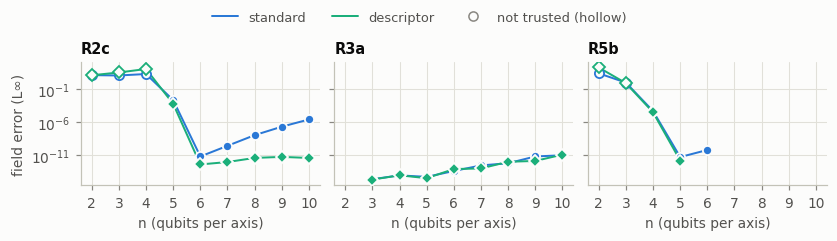

In [3]:
plotting.by_resolution(builds, "field_err_linf", "field error (L∞)", problems=PROBLEMS);

The filter's degree a preparation needs, from the resource estimates (T3).

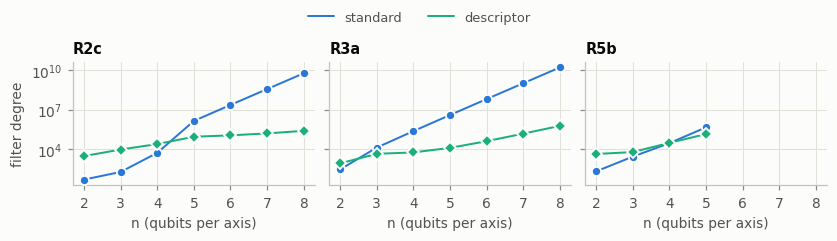

In [4]:
plotting.by_resolution(estimates, "degree", "filter degree", problems=PROBLEMS);

**What this does not show.** The standard form's faithful variants, which set the paper's
invariants against these datum slices, are notebook 11's; the other panels are notebooks 40–42's.